# Mini-Project: Data Analysis for Marketing Strategy
**Week 3, Day 5 – US Superstore dataset**

**Goal:** find out which states, cities and customers matter most for sales and profit, and use that to decide where to focus marketing.

How this notebook works: every code cell has a short comment on each line saying what it does, and under each chart there is a plain-English answer to the question.

## 1. Load and preprocess the data

First we bring in the tools (libraries) we need, then read the csv file into a table (a pandas *DataFrame*).

In [1]:
import pandas as pd  # pandas = tables of data (called DataFrames)
import numpy as np  # numpy = number helpers (we use it to round up)
import matplotlib.pyplot as plt  # matplotlib = the main chart library
import seaborn as sns  # seaborn = nicer looking charts built on top of matplotlib

sns.set_theme(style="whitegrid")  # use a clean white background with light grid lines for every chart
pd.options.display.float_format = "{:,.1f}".format  # show numbers with commas and 1 decimal place

In [2]:
DATA_PATH = "../Day4/superstore_dataset.csv"  # where the csv file is (it sits in the Day4 folder); change this if yours is somewhere else
df = pd.read_csv(DATA_PATH, encoding="latin-1")  # read the csv into a table; latin-1 is needed because the file has special characters
print(df.shape)  # prints (number of rows, number of columns)
display(df.head())  # shows the first 5 rows so we can see what the data looks like

(9994, 21)
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID    Customer Name    Segment        Country             City       State  Postal Code Region       Product ID         Category Sub-Category                                                 Product Name  Sales  Quantity  Discount  Profit
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520      Claire Gute   Consumer  United States        Henderson    Kentucky        42420  South  FUR-BO-10001798        Furniture    Bookcases                            Bush Somerset Collection Bookcase  262.0         2       0.0    41.9
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520      Claire Gute   Consumer  United States        Henderson    Kentucky        42420  South  FUR-CH-10000454        Furniture       Chairs  Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back  731.9         3       0.0   219.6
2       3  CA-2016-138688   6/12/2016   6/16/2016 

**Cleaning checks.** Before analysing anything we check for empty cells and duplicate rows, and we turn the date columns from plain text into real dates (so Python understands they are dates).

In [3]:
print(df.isna().sum().sum(), "missing values")  # isna() marks empty cells, sum() twice adds them all up
print(df.duplicated().sum(), "duplicate rows")  # counts rows that appear more than once
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")  # turn the text in Order Date into real dates (month/day/year)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")  # same for Ship Date
df["Year"] = df["Order Date"].dt.year  # make a new column that holds only the year
print(df["Order Date"].min().date(), "to", df["Order Date"].max().date())  # the first and last order date in the data
print(list(df["Country"].unique()))  # which countries are in the data
print("Total sales:", round(df["Sales"].sum()), "| Total profit:", round(df["Profit"].sum()))  # the big totals, for reference

0 missing values
0 duplicate rows
2014-01-03 to 2017-12-30
['United States']
Total sales: 2297201 | Total profit: 286397


**What we learned:** the data is clean (no missing values, no duplicates). It covers orders from January 2014 to December 2017 and **only one country, the United States**, so "area analysis" means comparing states and cities.

## 2. Which states have the most sales?

State
California     457,687.6
New York       310,876.3
Texas          170,188.0
Washington     138,641.3
Pennsylvania   116,511.9
Florida         89,473.7
Illinois        80,166.1
Ohio            78,258.1
Michigan        76,269.6
Virginia        70,636.7
Name: Sales, dtype: float64


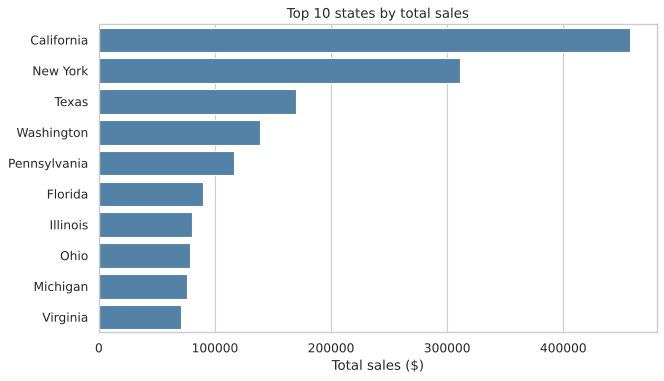

In [4]:
sales_by_state = df.groupby("State")["Sales"].sum().sort_values(ascending=False)  # add up Sales for each state, biggest first
top10_states = sales_by_state.head(10)  # keep only the first 10 states
print(top10_states)  # show the numbers

plt.figure(figsize=(9, 5))  # create an empty chart, 9 inches wide and 5 tall
sns.barplot(x=top10_states.values, y=top10_states.index, color="steelblue")  # horizontal bars: sales on the x axis, state names on the y axis
plt.title("Top 10 states by total sales")  # chart title
plt.xlabel("Total sales ($)")  # label under the chart
plt.ylabel("")  # no label needed on the side
plt.show()  # draw the chart

**Answer:** California is far ahead with about $457.7k, then New York ($310.9k), Texas ($170.2k), Washington ($138.6k) and Pennsylvania ($116.5k). The top two states alone are about a third of all sales.

## 3. New York vs California: sales and profit

               Sales   Profit  Profit margin %
State                                         
California 457,687.6 76,381.4             16.7
New York   310,876.3 74,038.5             23.8


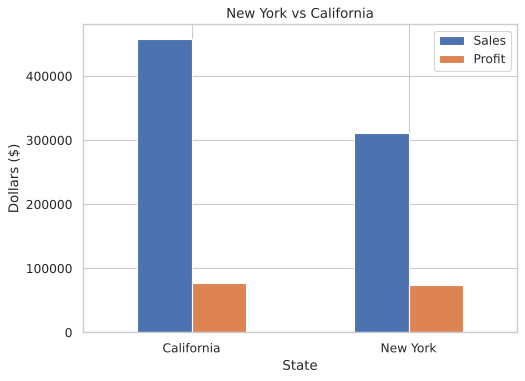

In [5]:
two_states = df[df["State"].isin(["New York", "California"])]  # keep only the rows from these two states
compare = two_states.groupby("State")[["Sales", "Profit"]].sum()  # total sales and total profit for each of them
compare["Profit margin %"] = compare["Profit"] / compare["Sales"] * 100  # profit as a % of sales (how much we keep from each dollar sold)
print(compare)  # show the table

compare[["Sales", "Profit"]].plot(kind="bar", figsize=(7, 5))  # bars for sales and profit, side by side for each state
plt.title("New York vs California")  # chart title
plt.ylabel("Dollars ($)")  # label on the side
plt.xticks(rotation=0)  # keep the state names horizontal so they are easy to read
plt.show()  # draw the chart

**Answer:** California sells about 47% more than New York ($457.7k vs $310.9k), **but the profit is almost the same** (about $76.4k vs $74.0k). So New York keeps 23.8 cents of every dollar sold, while California keeps only 16.7 cents. New York is the more efficient state.

## 4. Who is an outstanding customer in New York?
I define "outstanding" as the customer who brings the most **profit** (not just the most sales), because a big sale that loses money is not outstanding.

                    Sales  Profit
Customer Name                    
Tom Ashbrook     13,723.5 4,599.2
Keith Dawkins     5,854.2 2,510.9
Karen Daniels     6,241.3 2,283.0
Nathan Mautz      4,821.3 2,247.2
Tom Boeckenhauer  7,000.0 2,240.0
Steven Roelle     3,904.7 1,864.0
Pete Kriz         4,816.7 1,695.3
Darrin Martin     4,283.8 1,599.7
Todd Sumrall      6,492.3 1,575.0
Seth Vernon       7,359.9 1,571.8


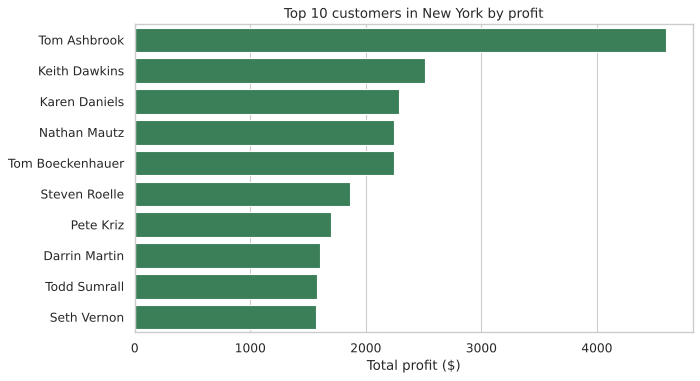

In [6]:
ny = df[df["State"] == "New York"]  # keep only the New York rows
ny_customers = ny.groupby("Customer Name")[["Sales", "Profit"]].sum()  # total sales and profit for each customer in New York
ny_customers = ny_customers.sort_values("Profit", ascending=False)  # best profit first
top10_ny = ny_customers.head(10)  # keep the top 10
print(top10_ny)  # show the table

plt.figure(figsize=(9, 5))  # new empty chart
sns.barplot(x=top10_ny["Profit"], y=top10_ny.index, color="seagreen")  # bars of profit for each of the top 10 customers
plt.title("Top 10 customers in New York by profit")  # chart title
plt.xlabel("Total profit ($)")  # label under the chart
plt.ylabel("")  # no label on the side
plt.show()  # draw the chart

**Answer:** **Tom Ashbrook** is the outstanding customer in New York: about $4.6k profit from $13.7k of sales. He is well ahead of the next one, Keith Dawkins (about $2.5k profit).

## 5. Are there differences in profitability between states?

10 states lose money, out of 49
                   Sales    Profit  Avg_Discount  Margin %
State                                                     
Texas          170,188.0 -25,729.4          37.0     -15.1
Ohio            78,258.1 -16,971.4          32.5     -21.7
Pennsylvania   116,511.9 -15,560.0          32.9     -13.4
Illinois        80,166.1 -12,607.9          39.0     -15.7
North Carolina  55,603.2  -7,490.9          28.4     -13.5
Colorado        32,108.1  -6,527.9          31.6     -20.3
Average discount in losing states: 32.0 %
Average discount in the other states: 2.3 %


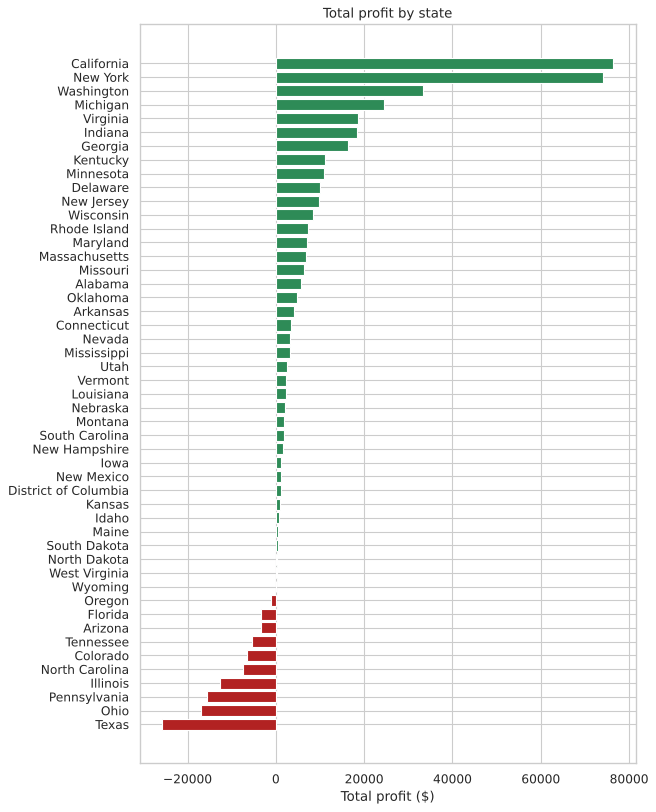

In [7]:
state_summary = df.groupby("State").agg(  # group the rows by state and calculate several numbers at once
    Sales=("Sales", "sum"),  # total sales
    Profit=("Profit", "sum"),  # total profit
    Avg_Discount=("Discount", "mean"),  # the average discount given (as a fraction, e.g. 0.3 = 30%)
)
state_summary["Avg_Discount"] = state_summary["Avg_Discount"] * 100  # turn the fraction into a % (0.3 becomes 30)
state_summary["Margin %"] = state_summary["Profit"] / state_summary["Sales"] * 100  # profit as a % of sales

profit_by_state = state_summary["Profit"].sort_values()  # states sorted from the biggest loss to the biggest profit
colors = ["firebrick" if p < 0 else "seagreen" for p in profit_by_state]  # red bar for a loss, green bar for a profit

plt.figure(figsize=(8, 12))  # a tall chart because there are many states
plt.barh(profit_by_state.index, profit_by_state.values, color=colors)  # horizontal bars of profit for every state
plt.title("Total profit by state")  # chart title
plt.xlabel("Total profit ($)")  # label under the chart
plt.show()  # draw the chart

losing = state_summary[state_summary["Profit"] < 0]  # only the states that lose money
print(len(losing), "states lose money, out of", len(state_summary))  # how many
print(losing.sort_values("Profit").head(6))  # the 6 worst states
print("Average discount in losing states:", round(losing["Avg_Discount"].mean(), 1), "%")  # how big the discounts are where we lose money
print("Average discount in the other states:", round(state_summary[state_summary["Profit"] >= 0]["Avg_Discount"].mean(), 1), "%")  # and where we make money

**Answer:** Yes, big differences. **10 of the 49 states lose money.** The worst are Texas (-$25.7k), Ohio (-$17.0k), Pennsylvania (-$15.6k) and Illinois (-$12.6k). Several of them are among the biggest sellers, so high sales do not mean high profit.

The clue is in the last two lines: the states that lose money give an **average discount of about 32%**, while the other states give only about **2%**. Heavy discounting is the likely reason for the losses.

## 6. Pareto principle: do 20% of customers bring 80% of the profit?
We sort the customers from the most profitable to the least, and then keep a running total ("cumulative") of their profit.

793 customers; the top 20% = 159 customers
They bring 81.7 % of the profit
It takes 153 customers ( 19.3 %) to reach 80% of profit


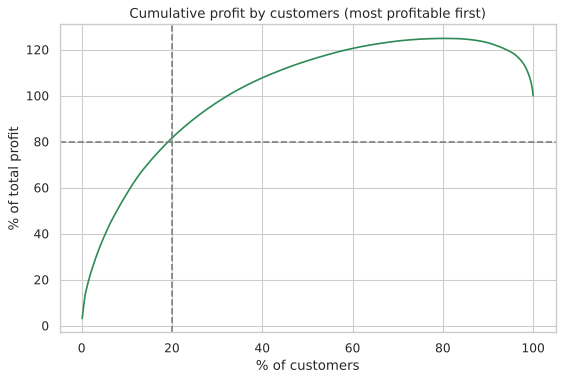

In [8]:
cust = df.groupby("Customer Name")[["Sales", "Profit"]].sum()  # total sales and profit for each customer
cust_profit = cust["Profit"].sort_values(ascending=False)  # profit per customer, most profitable first
cum_profit = cust_profit.cumsum() / cust_profit.sum() * 100  # running total of profit, as a % of the total profit
n_customers = len(cust_profit)  # how many customers there are
top20_count = int(np.ceil(0.2 * n_customers))  # how many customers are 20% of them (rounded up)
share = cum_profit.iloc[top20_count - 1]  # the running % at the 20% mark
needed = int((cum_profit < 80).sum() + 1)  # how many customers it takes to reach 80% of profit
print(n_customers, "customers; the top 20% =", top20_count, "customers")  # the sizes
print("They bring", round(share, 1), "% of the profit")  # answer to the question
print("It takes", needed, "customers (", round(needed / n_customers * 100, 1), "%) to reach 80% of profit")  # the other way around

x = np.arange(1, n_customers + 1) / n_customers * 100  # x axis: % of customers (from near 0 to 100)
plt.figure(figsize=(8, 5))  # new empty chart
plt.plot(x, cum_profit.values, color="seagreen")  # the cumulative profit curve
plt.axvline(20, linestyle="--", color="grey")  # vertical dashed line at 20% of customers
plt.axhline(80, linestyle="--", color="grey")  # horizontal dashed line at 80% of profit
plt.title("Cumulative profit by customers (most profitable first)")  # chart title
plt.xlabel("% of customers")  # x label
plt.ylabel("% of total profit")  # y label
plt.show()  # draw the chart

**Answer:** **Yes.** The top 20% of customers (159 of 793) bring about **81.7% of the profit**, and 80% of the profit is reached with only 19.3% of the customers. The Pareto rule fits the profit very well.

## 7. Top 20 cities by sales and by profit
Some city names exist in more than one state (for example Springfield or Columbus), so I group by **city and state together**.

                     Label     Sales    Profit  Margin %
   New York City, New York 256,368.2  62,037.0      24.2
   Los Angeles, California 175,851.3  30,440.8      17.3
       Seattle, Washington 119,540.7  29,156.1      24.4
 San Francisco, California 112,669.1  17,507.4      15.5
Philadelphia, Pennsylvania 109,077.0 -13,837.8     -12.7
            Houston, Texas  64,504.8 -10,153.5     -15.7
         Chicago, Illinois  48,539.5  -6,654.6     -13.7
     San Diego, California  47,521.0   6,377.2      13.4
         Detroit, Michigan  42,446.9  13,181.8      31.1
     Jacksonville, Florida  39,133.3  -2,445.7      -6.2
        San Antonio, Texas  21,843.5  -7,299.1     -33.4
          Newark, Delaware  20,448.0   8,086.2      39.5
             Dallas, Texas  20,131.9  -2,846.5     -14.1
        Lafayette, Indiana  19,630.5   8,976.1      45.7
          Atlanta, Georgia  17,197.8   6,993.7      40.7
    Minneapolis, Minnesota  16,870.5   6,824.6      40.5
     Springfield, Virginia  16,

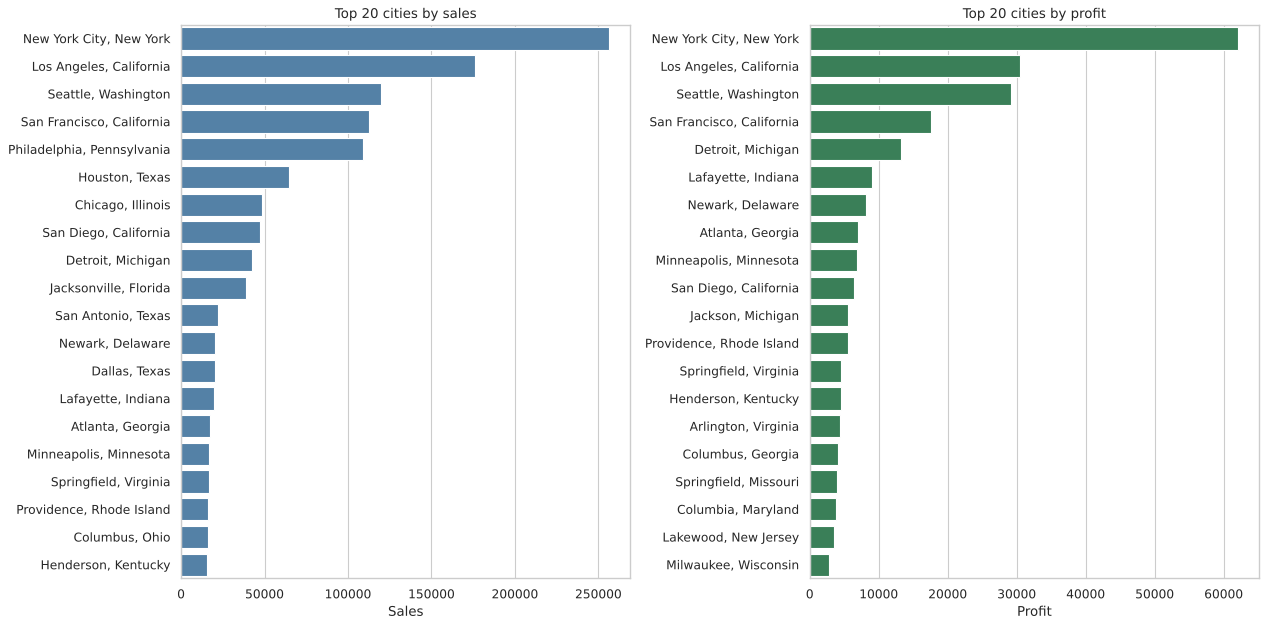

In [9]:
city = df.groupby(["City", "State"])[["Sales", "Profit"]].sum().reset_index()  # totals for each city (together with its state)
city["Label"] = city["City"] + ", " + city["State"]  # a readable name like "Houston, Texas"
city["Margin %"] = city["Profit"] / city["Sales"] * 100  # profit as a % of sales for each city
top_sales = city.sort_values("Sales", ascending=False).head(20)  # the 20 cities with the most sales
top_profit = city.sort_values("Profit", ascending=False).head(20)  # the 20 cities with the most profit

fig, axes = plt.subplots(1, 2, figsize=(16, 8))  # one picture with two charts next to each other
sns.barplot(data=top_sales, x="Sales", y="Label", color="steelblue", ax=axes[0])  # left chart: top 20 by sales
axes[0].set_title("Top 20 cities by sales")  # left title
axes[0].set_ylabel("")  # no side label
sns.barplot(data=top_profit, x="Profit", y="Label", color="seagreen", ax=axes[1])  # right chart: top 20 by profit
axes[1].set_title("Top 20 cities by profit")  # right title
axes[1].set_ylabel("")  # no side label
plt.tight_layout()  # stop the labels from overlapping
plt.show()  # draw both charts

print(top_sales[["Label", "Sales", "Profit", "Margin %"]].to_string(index=False))  # table of the top 20 by sales with their profit
overlap = set(top_sales["Label"]) & set(top_profit["Label"])  # cities that are in both top 20 lists
print("Cities in both lists:", len(overlap))  # how many
print("Top-20 sales cities that lose money:", list(top_sales[top_sales["Profit"] < 0]["Label"]))  # the big sellers with a negative profit

**Answer:** The two lists are not the same: only 13 cities are in both. **New York City** is first on both lists, followed by Los Angeles, Seattle and San Francisco.

Profitability differs a lot between cities. Among the 20 biggest cities by sales, **7 lose money**: Philadelphia, Houston, Chicago, Jacksonville, San Antonio, Dallas and Columbus (Ohio). On the other side, smaller cities like Lafayette (Indiana), Atlanta, Minneapolis and Newark (Delaware) keep around 40% of their sales as profit.

## 8. Top 20 customers by sales

                      Sales   Profit
Customer Name                       
Sean Miller        25,043.0 -1,980.7
Tamara Chand       19,052.2  8,981.3
Raymond Buch       15,117.3  6,976.1
Tom Ashbrook       14,595.6  4,703.8
Adrian Barton      14,473.6  5,444.8
Ken Lonsdale       14,175.2    806.9
Sanjit Chand       14,142.3  5,757.4
Hunter Lopez       12,873.3  5,622.4
Sanjit Engle       12,209.4  2,650.7
Christopher Conant 12,129.1  2,177.0
Todd Sumrall       11,891.8  2,371.7
Greg Tran          11,820.1  2,163.4
Becky Martin       11,789.6 -1,660.0
Seth Vernon        11,470.9  1,199.4
Caroline Jumper    11,165.0    858.7
Clay Ludtke        10,880.5  1,933.8
Maria Etezadi      10,663.7  1,859.5
Karen Ferguson     10,604.3  1,660.1
Bill Shonely       10,501.7  2,616.1
Edward Hooks       10,310.9  1,393.5


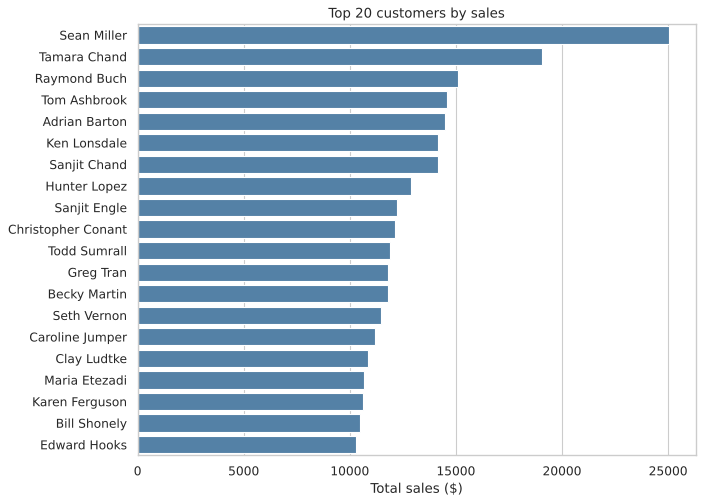

In [10]:
top20_customers = cust.sort_values("Sales", ascending=False).head(20)  # the 20 customers with the highest total sales
print(top20_customers)  # show the table (with their profit too)

plt.figure(figsize=(9, 7))  # new empty chart
sns.barplot(x=top20_customers["Sales"], y=top20_customers.index, color="steelblue")  # bars of sales for each of the top 20 customers
plt.title("Top 20 customers by sales")  # chart title
plt.xlabel("Total sales ($)")  # label under the chart
plt.ylabel("")  # no label on the side
plt.show()  # draw the chart

**Answer:** The biggest customer by sales is **Sean Miller** ($25.0k), then Tamara Chand ($19.1k), Raymond Buch ($15.1k), Tom Ashbrook ($14.6k) and Adrian Barton ($14.5k). Note that Sean Miller actually **lost** about $2.0k of profit, so the biggest customer is not a good one.

## 9. Cumulative curve of sales by customers: does Pareto apply to sales?

Top 20% of customers bring 48.1 % of the sales
It takes 396 customers ( 49.9 %) to reach 80% of sales


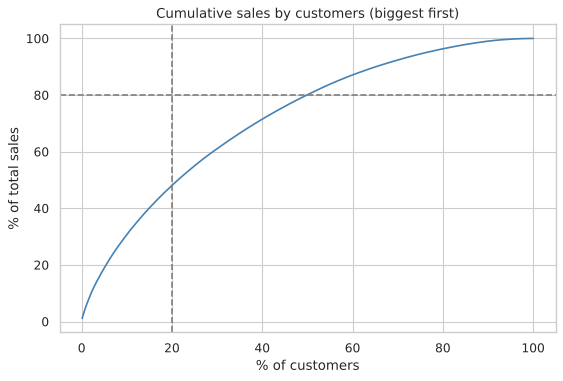

In [11]:
cust_sales = cust["Sales"].sort_values(ascending=False)  # sales per customer, biggest first
cum_sales = cust_sales.cumsum() / cust_sales.sum() * 100  # running total of sales as a % of the total sales
share_sales = cum_sales.iloc[top20_count - 1]  # the running % at the 20% mark of customers
needed_sales = int((cum_sales < 80).sum() + 1)  # how many customers it takes to reach 80% of sales
print("Top 20% of customers bring", round(share_sales, 1), "% of the sales")  # answer to the question
print("It takes", needed_sales, "customers (", round(needed_sales / n_customers * 100, 1), "%) to reach 80% of sales")  # the other way around

plt.figure(figsize=(8, 5))  # new empty chart
plt.plot(x, cum_sales.values, color="steelblue")  # the cumulative sales curve (x is the same % of customers as before)
plt.axvline(20, linestyle="--", color="grey")  # vertical dashed line at 20% of customers
plt.axhline(80, linestyle="--", color="grey")  # horizontal dashed line at 80% of sales
plt.title("Cumulative sales by customers (biggest first)")  # chart title
plt.xlabel("% of customers")  # x label
plt.ylabel("% of total sales")  # y label
plt.show()  # draw the chart

**Answer:** **No, not for sales.** The top 20% of customers bring only about **48.1% of the sales**, and you need about half of the customers (49.9%) to reach 80% of sales. Sales are spread out much more evenly than profit.

This is a useful contrast: profit is concentrated in a small group of customers (Pareto works), but sales are not.

## 10. Decision: which states and cities to prioritize?
Here I put the main numbers together: states that make good profit with a healthy margin, and the cities inside them.

In [12]:
good_states = state_summary[state_summary["Profit"] > 0].sort_values("Profit", ascending=False).head(8)  # the 8 states with the highest profit
print(good_states[["Sales", "Profit", "Margin %", "Avg_Discount"]])  # their sales, profit, margin and average discount (in %)

best_cities = city[city["Profit"] > 0].sort_values("Profit", ascending=False).head(10)  # the 10 most profitable cities
print(best_cities[["Label", "Sales", "Profit", "Margin %"]].to_string(index=False))  # show them

               Sales   Profit  Margin %  Avg_Discount
State                                                
California 457,687.6 76,381.4      16.7           7.3
New York   310,876.3 74,038.5      23.8           5.5
Washington 138,641.3 33,402.7      24.1           6.4
Michigan    76,269.6 24,463.2      32.1           0.7
Virginia    70,636.7 18,598.0      26.3           0.0
Indiana     53,555.4 18,382.9      34.3           0.0
Georgia     49,095.8 16,250.0      33.1           0.0
Kentucky    36,591.8 11,199.7      30.6           0.0
                    Label     Sales   Profit  Margin %
  New York City, New York 256,368.2 62,037.0      24.2
  Los Angeles, California 175,851.3 30,440.8      17.3
      Seattle, Washington 119,540.7 29,156.1      24.4
San Francisco, California 112,669.1 17,507.4      15.5
        Detroit, Michigan  42,446.9 13,181.8      31.1
       Lafayette, Indiana  19,630.5  8,976.1      45.7
         Newark, Delaware  20,448.0  8,086.2      39.5
         Atlanta, Ge

### Recommendations

**Prioritize (invest more marketing here):**
- **California** (Los Angeles, San Francisco): the biggest market and about $76k profit. Marketing should aim at growing sales while keeping the margin healthy (it is lower than New York).
- **New York** (New York City): almost the same profit as California from much lower sales, and a better margin (23.8%). New York City alone is the top city for both sales and profit.
- **Washington** (Seattle): high profit and a healthy margin (about 24%).
- **Michigan** (Detroit): small but very efficient, with high margins and almost no discounting.
- **Small high-margin cities** such as Lafayette, Atlanta, Minneapolis and Newark: they keep around 40% of sales as profit, so they are good places to test new campaigns.

**Fix before spending more:**
- **Texas, Ohio, Pennsylvania and Illinois** are big markets that lose money, and they give discounts of around 32-39% on average. More marketing here would just bring more loss-making sales. The first step is to review the discount policy there.
- Loss-making big cities like **Philadelphia, Houston and Chicago** need the same discount review.

**Customers:** profit is concentrated (20% of customers bring about 82% of profit), so marketing should focus on keeping the most profitable customers happy (for example a loyalty offer), and not just on the customers who spend the most, because the top spender (Sean Miller) loses money.